## Чем активнее пользователи, тем выше нагрузка на серверы, а жалобы на «подвисания» приложения становятся чаще. Нужно спрогнозировать, как изменится активность в течение ближайшего месяца, и ответить на три вопроса:

- Что прогнозировать и как? Метрика, временное разрешение, регрессоры.
- Хватает ли данных для проверки прогноза? Если нет, то на какой горизонт можно честно проверить модель.
- Какую модель выбрать и чему верить? Интерпретация результатов и ограничения.

In [1]:
import os, warnings, getpass, logging
import numpy as np
import pandas as pd
import pandahouse
import matplotlib.pyplot as plt
import seaborn as sns
from orbit.models import DLT
from orbit.diagnostics.plot import plot_predicted_components

warnings.filterwarnings("ignore")
logging.getLogger('orbit').setLevel(logging.WARNING)                 
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR) 
sns.set(rc={"figure.figsize": (16, 6)}, style="whitegrid")

PROMO_START, PROMO_END = "2026-09-11", "2026-09-18"   
FORECAST_DAYS = 30
INIT_DAYS = 28                       
STEP_DAYS = 7                        
HORIZONS = [7, 14, 23]               
DAMPING_GRID = [0.8, 0.9, 0.95]      
TRAIN_STARTS = ["2026-08-01", "2026-08-15"]  
USE_MCMC_FOR_FINAL = True
SEED = 42
OUT_DIR = "forecast_output"
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Выгрузка из ClickHouse

In [3]:
connection = {
    'host': '',
    'password': '',
    'user': '',
    'database': ''
}

query = '''
SELECT toStartOfHour(time) AS hour_time,
       count() AS events
FROM simulator_20260920.feed_actions
GROUP BY hour_time
ORDER BY hour_time
'''

activity = pandahouse.read_clickhouse(query=query, connection=connection)
activity['hour_time'] = pd.to_datetime(activity['hour_time'])
activity = activity.sort_values('hour_time').reset_index(drop=True)
print(activity.hour_time.min(), '..', activity.hour_time.max(), '| строк:', len(activity))

2026-08-01 00:00:00 .. 2026-10-11 19:00:00 | строк: 1724


## 2. Подготовка ряда
- Последний (неполный) час отбрасываем, пропуски заполняем нулями.
- **Акция:** значения за 11–17.09 заменяем на значения того же часа неделей раньше (`events_clean`).
  Берём только прошлую неделю, чтобы не использовать «будущие» данные в бэктестинге. Эффект акции считаем отдельно.

In [4]:
act = activity.iloc[:-1].copy()
full_idx = pd.date_range(act.hour_time.min(), act.hour_time.max(), freq='h')
print('Пропущенных часов:', len(full_idx) - len(act))
act = (act.set_index('hour_time').reindex(full_idx, fill_value=0)
          .rename_axis('hour_time').reset_index())

act['promo'] = ((act.hour_time >= PROMO_START) & (act.hour_time < PROMO_END)).astype(int)
act['events_clean'] = act['events'].astype(float)
pm = act.promo == 1
act.loc[pm, 'events_clean'] = act['events'].shift(24 * 7)[pm]       # контрафакт: тот же час неделей раньше
assert act.events_clean.notna().all()

act['y'] = np.log1p(act['events_clean'])
act['dow'] = act.hour_time.dt.dayofweek
act['hour'] = act.hour_time.dt.hour
DOW_REGS = [f'dow_{d}' for d in range(1, 7)]                          
for d in range(1, 7):
    act[f'dow_{d}'] = (act.dow == d).astype(int)

# эффект акции (по сравнению с контрафактом)
up_total = act.loc[pm, 'events'].sum() / act.loc[pm, 'events_clean'].sum() - 1
up_peak = act.loc[pm, 'events'].max() / act.loc[pm, 'events_clean'].max() - 1
print(f'Эффект акции: суммарно {up_total:+.0%}, в пиковый час {up_peak:+.0%} '
      f'(оценка снизу: рост аудитории за неделю не учтён)')
print('Максимум событий/час: факт (с акцией) =', int(act.events.max()),
      '| без акции =', int(act.loc[~pm, 'events'].max()))

n_hours = len(act)
print(f'Часов: {n_hours}, полных суток: {n_hours // 24}')

Пропущенных часов: 0
Эффект акции: суммарно +98%, в пиковый час +103% (оценка снизу: рост аудитории за неделю не учтён)
Максимум событий/час: факт (с акцией) = 95649 | без акции = 72552
Часов: 1723, полных суток: 71


## 3. EDA

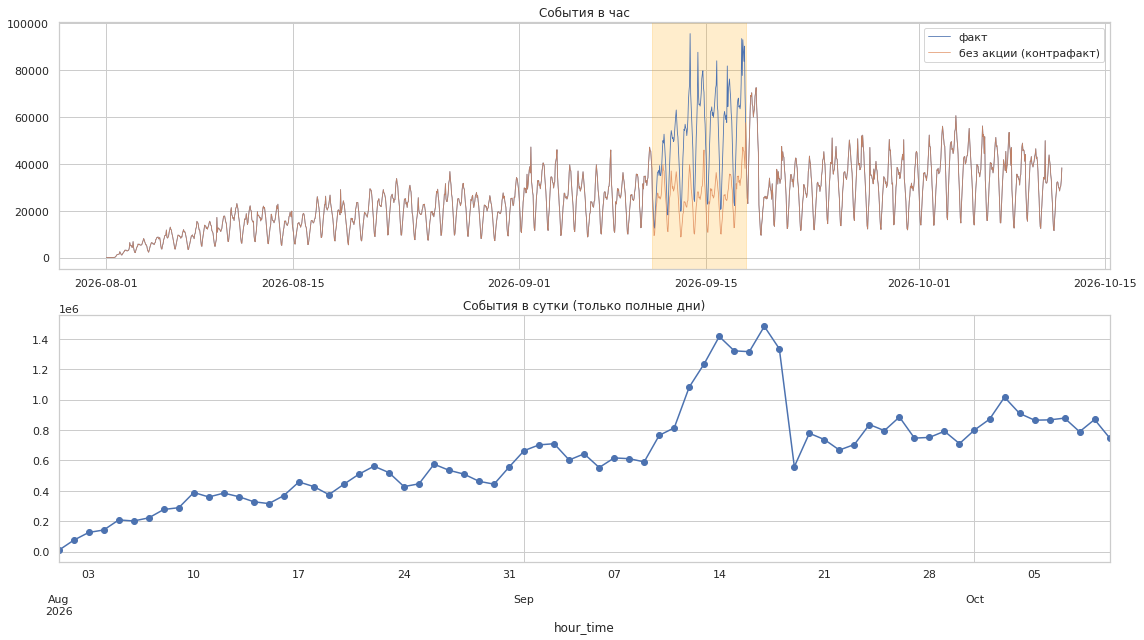

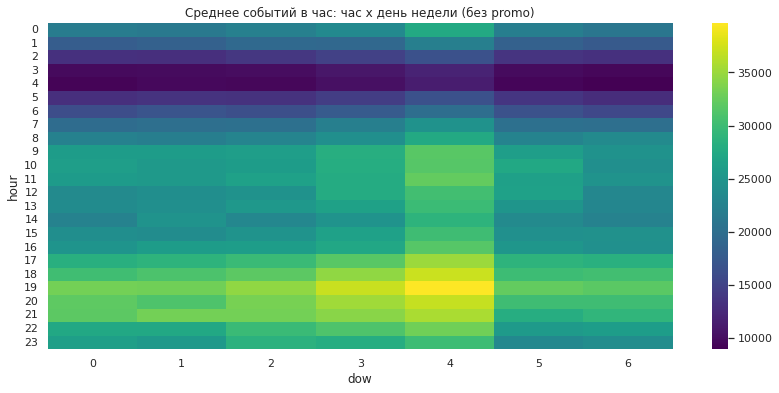

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(16, 9))
ax[0].plot(act.hour_time, act.events, lw=0.8, label='факт')
ax[0].plot(act.hour_time, act.events_clean, lw=0.8, label='без акции (контрафакт)', alpha=0.8)
ax[0].axvspan(pd.Timestamp(PROMO_START), pd.Timestamp(PROMO_END), color='orange', alpha=0.2)
ax[0].set_title('События в час'); ax[0].legend()
daily = act.set_index('hour_time')['events'].resample('D').sum()
daily = daily[daily.index < act.hour_time.max().normalize()]     # последние сутки неполные — не рисуем
daily.plot(ax=ax[1], marker='o'); ax[1].set_title('События в сутки (только полные дни)')
plt.tight_layout(); plt.show()

prof = act[act.promo == 0].pivot_table(index='hour', columns='dow', values='events', aggfunc='mean')
plt.figure(figsize=(14, 6)); sns.heatmap(prof, cmap='viridis')
plt.title('Среднее событий в час: час x день недели (без promo)'); plt.show()

## Ответ на вопрос 1. Метрика, разрешение, регрессоры

**Метрика:** число событий (view + like) в час. Каждое действие в ленте — обращение к бэкенду, поэтому общее число событий напрямую отражает нагрузку на серверы. DAU не подходит (не учитывает интенсивность: число людей прежнее, а нагрузка может расти), CTR описывает качество контента, а не нагрузку. Прогнозируется log1p(events): сезонность становится мультипликативной, прогноз не уходит в отрицательные значения.

**Разрешение: 1 час.** Серверам важны пиковые часы, а не суточное среднее. Часовой ряд (1716 точек, ~10 недельных циклов) показывает суточный цикл, а суточный ряд (71 точка) его скрыл бы.

**Регрессоры:**
- день недели (6 бинарных признаков), известен заранее;
- акция 11–17.09 как регрессор НЕ включена: в первом запуске promo дал +5.7% при фактическом росте ~+100% (гибкий уровень модели поглотил скачок). Вместо этого неделя акции заменена контрафактом (значение того же часа неделей раньше), а эффект акции оценён отдельно: **+98% по сумме, +103% в пиковый час** (оценка снизу);
- source, exp_group, country, os не включены: их будущие значения неизвестны;
- праздники не включены: в истории их нет, эффект оценить нельзя;
- первые недели ряда — запуск с нуля, поэтому сравнивались обучение с 01.08 и с 15.08 (лучше с 15.08).

## 4. Метрики, модели, baseline'ы

In [6]:
def wape(y, f):
    y, f = np.asarray(y, float), np.asarray(f, float)
    return np.abs(y - f).sum() / np.abs(y).sum()

def smape(y, f):
    y, f = np.asarray(y, float), np.asarray(f, float)
    return np.mean(2 * np.abs(y - f) / (np.abs(y) + np.abs(f) + 1e-9))

def peak_metrics(y, f, q=0.95):
    y, f = np.asarray(y, float), np.asarray(f, float)
    m = y >= np.quantile(y, q)
    return wape(y[m], f[m]), np.mean((f[m] - y[m]) / y[m])

def regs_of(kind):
    return DOW_REGS if kind == 'DLT24' else []

def make_model(name, estimator='stan-map'):
    kind, damp, start = name
    kw = dict(response_col='y', date_col='hour_time', estimator=estimator, seed=SEED, damped_factor=damp)
    if estimator == 'stan-mcmc':
        kw.update(num_warmup=2000, num_sample=1000)
    if kind == 'DLT24':
        kw.update(seasonality=24, regressor_col=DOW_REGS, regressor_sign=['='] * len(DOW_REGS))
    else:
        kw.update(seasonality=168)
    return DLT(**kw)

def label(name):
    return f'{name[0]}_d{name[1]}_from{name[2][5:]}'

CANDIDATES = [(k, d, s) for s in TRAIN_STARTS for k in ('DLT24', 'DLT168') for d in DAMPING_GRID]

BASELINES = {'base_all': None, 'base_lastweek': 1, 'base_2weeks': 2}  

def profile_forecast(train, test, weeks):
    t = train if weeks is None else train.tail(24 * 7 * weeks)
    mean = t.groupby(['dow', 'hour'])['events_clean'].mean()
    idx = pd.MultiIndex.from_arrays([test.dow, test.hour])
    return mean.reindex(idx).fillna(t['events_clean'].mean()).values

## 5. Бэктестинг (rolling origin, расширяющееся окно)
Фолды, где тест пересекается с акцией, пропускаются. Для выбора модели используются **только фолды после акции**
(они общие для обоих вариантов начала обучения). Может идти несколько минут.

In [7]:
last_end = act.hour_time.max() + pd.Timedelta(hours=1)
t_min = act.hour_time.min().normalize()
promo_s, promo_e = pd.Timestamp(PROMO_START), pd.Timestamp(PROMO_END)

def cuts_for(h):
    first = t_min + pd.Timedelta(days=INIT_DAYS)
    c, out = first, []
    while c + pd.Timedelta(days=h) <= last_end:
        out.append(c); c += pd.Timedelta(days=STEP_DAYS)
    last_c = (last_end - pd.Timedelta(days=h)).floor('D')       
    if last_c >= first and (not out or last_c > out[-1] + pd.Timedelta(days=3)):
        out.append(last_c)  
    return out

rows, store = [], {}
def add_row(model, h, cut, test, f):
    pw, pb = peak_metrics(test.events, f)
    rows.append(dict(horizon=h, cut=cut, model=model, wape=wape(test.events, f), smape=smape(test.events, f),
                     mae=np.mean(np.abs(test.events.values - f)), peak_wape=pw, peak_bias=pb))
    store[(model, h, cut)] = pd.DataFrame({'hour_time': test.hour_time.values,
                                           'actual': test.events.values, 'forecast': f})

for h in HORIZONS:
    for cut in cuts_for(h):
        end = cut + pd.Timedelta(days=h)
        if (cut < promo_e) and (end > promo_s):
            continue
        train = act[act.hour_time < cut]
        test = act[(act.hour_time >= cut) & (act.hour_time < end)]
        if len(test) < 24 * h * 0.9:
            continue

        for bname, weeks in BASELINES.items():
            add_row(bname, h, cut, test, profile_forecast(train, test, weeks))

        for name in CANDIDATES:
            kind, damp, start = name
            tr = train[train.hour_time >= pd.Timestamp(start)]
            if (cut - pd.Timestamp(start)).days < INIT_DAYS:
                continue
            try:
                regs = regs_of(kind)
                m = make_model(name)
                m.fit(tr[['hour_time', 'y'] + regs])
                p = m.predict(df=test[['hour_time'] + regs])
                add_row(label(name), h, cut, test, np.expm1(p['prediction'].values))
            except Exception as e:
                print(f'[warn] {label(name)} h={h} cut={cut:%Y-%m-%d}: {e}')
        print(f'готов фолд: horizon={h}д, cut={cut:%Y-%m-%d}')

bt = pd.DataFrame(rows)
bt.to_csv(f'{OUT_DIR}/backtest_folds.csv', index=False)
assert not bt.empty, 'Не нашлось ни одного чистого фолда.'

готов фолд: horizon=7д, cut=2026-08-29
готов фолд: horizon=7д, cut=2026-09-19
готов фолд: horizon=7д, cut=2026-09-26
готов фолд: horizon=7д, cut=2026-10-03
готов фолд: horizon=14д, cut=2026-09-19
готов фолд: horizon=14д, cut=2026-09-26
готов фолд: horizon=23д, cut=2026-09-18


## Ответ на вопрос 2. Валидация и достаточность данных

**Модель:** DLT (Orbit), сезонность 24 часа + дни недели, затухание тренда подбиралось по сетке (0.8 / 0.9 / 0.95).

**Валидация:** бэктестинг с расширяющимся окном: минимум 28 дней обучения, шаг 7 дней, горизонты 7, 14 и 23 дня. Фолды, где тест пересекается с акцией, исключены. Модели сравнивались только на фолдах после акции, с тремя baseline'ами (среднее по день недели×час за всю историю, за 1 и за 2 недели). Метрики: WAPE и ошибка/смещение в пиковых часах (занижение пика опаснее всего).

**Данных для горизонта 30 дней — не хватает.** Нужно ≥28 дней обучения + 30 дней чистого теста, а данных ~71.5 дня, и акция посередине исключает любые тестовые окна, которые её пересекают. Чистое окно после акции — ~23.5 дня.

**Горизонты, которые удалось проверить:** 7 дней (3 фолда), 14 дней (2 фолда), 23 дня (1 фолд). Фолдов мало и они пересекаются по времени, поэтому выводы о качестве предварительные; 30-дневный прогноз — экстраполяция без проверки.

## 6. Результаты и выбор модели (только фолды после акции)

Baseline'ы:


,wape,peak_wape,peak_bias,folds
model,,,,
base_2weeks,0.2074,0.2917,-0.2627,6
base_lastweek,0.2136,0.3185,-0.2305,6
base_all,0.3942,0.4959,-0.4935,6


Модели (топ-8):


,wape,peak_wape,peak_bias,folds
model,,,,
DLT24_d0.8_from08-15,0.1821,0.1732,-0.0948,6
DLT24_d0.95_from08-15,0.1913,0.1758,-0.0848,6
DLT24_d0.9_from08-15,0.1915,0.1762,-0.0850,6
DLT24_d0.9_from08-01,0.1977,0.1607,-0.0775,6
DLT24_d0.95_from08-01,0.2396,0.1743,-0.0321,6
DLT24_d0.8_from08-01,0.2425,0.1673,-0.0324,6
DLT168_d0.9_from08-15,0.2494,0.1967,0.0124,6
DLT168_d0.8_from08-15,0.3428,0.2379,0.0577,6


Лучшая модель: DLT24_d0.8_from08-15; WAPE=0.182 против лучшего baseline (base_2weeks) 0.207 (+12.2%)
Фолдов на горизонт (после акции): {7: 3, 14: 2, 23: 1} — мало, различия между близкими моделями — в пределах шума.


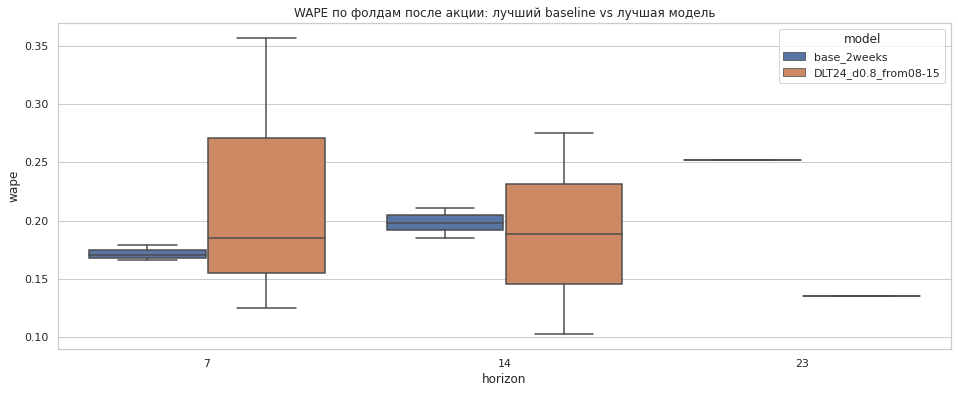

In [8]:
post = bt[bt.cut >= promo_e]
is_base = post.model.str.startswith('base_')

def score_table(df):
    return (df.groupby(['model', 'horizon']).agg(wape=('wape', 'mean'), peak_wape=('peak_wape', 'mean'),
                                                 peak_bias=('peak_bias', 'mean'), folds=('wape', 'size'))
              .groupby('model').agg(wape=('wape', 'mean'), peak_wape=('peak_wape', 'mean'),
                                    peak_bias=('peak_bias', 'mean'), folds=('folds', 'sum'))
              .sort_values('wape').round(4))

models_tbl, base_tbl = score_table(post[~is_base]), score_table(post[is_base])
print('Baseline\'ы:'); display(base_tbl)
print('Модели (топ-8):'); display(models_tbl.head(8))
pd.concat([base_tbl, models_tbl]).to_csv(f'{OUT_DIR}/backtest_summary.csv')

best_label = models_tbl.index[0]
best_name = next(n for n in CANDIDATES if label(n) == best_label)
best_w, base_w = models_tbl.wape.iloc[0], base_tbl.wape.iloc[0]
print(f'Лучшая модель: {best_label}; WAPE={best_w:.3f} против лучшего baseline ({base_tbl.index[0]}) {base_w:.3f} '
      f'({1 - best_w / base_w:+.1%})')
if best_w >= base_w:
    print('ВНИМАНИЕ: ни одна модель не обыграла лучший baseline — используйте baseline или пересмотрите модель.')
elif best_w > base_w * 0.9:
    print('ВНИМАНИЕ: выигрыш над лучшим baseline < 10% — в отчёте честно напишите это; '
          'сезонный профиль последних недель почти не хуже и проще.')
print(f'Фолдов на горизонт (после акции): {post[~is_base & (post.model == best_label)].groupby("horizon").size().to_dict()}'
      ' — мало, различия между близкими моделями — в пределах шума.')

plt.figure(figsize=(16, 6))
sns.boxplot(x='horizon', y='wape', hue='model', data=post[post.model.isin([base_tbl.index[0], best_label])])
plt.title('WAPE по фолдам после акции: лучший baseline vs лучшая модель'); plt.show()

## 7. Финальная модель, прогноз и верхняя граница для DevOps
`events_capacity` = прогноз × эмпирический коэффициент: 95-й перцентиль отношения факт/прогноз
в пиковых (по прогнозу, верхние 10%) часах лучшей модели в бэктестинге. Это реалистичнее MCMC-интервала.

chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

                                                                                                                                                                                                                                                                                                                                
Коэффициент запаса (P95 факт/прогноз в пиковые часы): x1.10


,events_total,peak_hour_forecast,peak_hour_capacity,peak_hour_model_p95,peak_events_per_sec_capacity
hour_time,,,,,
2026-10-11,181560.3,40819.8,44715.7,43940.8,12.4
2026-10-12,695047.0,41493.1,45453.3,57426.7,12.6
2026-10-13,674092.5,40362.1,44214.3,63673.9,12.3
2026-10-14,655097.0,39037.8,42763.6,69721.7,11.9
2026-10-15,651882.5,38913.3,42627.3,72614.2,11.8
2026-10-16,622596.1,37182.0,40730.7,76078.4,11.3
2026-10-17,617801.0,37406.4,40976.6,85305.1,11.4
2026-10-18,597023.9,36013.6,39450.8,84882.1,11.0
2026-10-19,602727.0,35699.9,39107.2,94240.9,10.9


Среднее событий/час: последние 7 дней факт = 34,188, первые 7 дней прогноза = 26,999 (-21.0%)
Максимум за всё время без акции: 72,552/час; с акцией: 95,649/час
Прогноз events_capacity (макс.): 45,453/час (~12.6 событий/сек); модельный P95 (макс.): 188,801/час
ВНИМАНИЕ: модельный P95 в разы выше любых наблюдавшихся значений — интервал тренда раздут, для планирования используйте events_capacity.


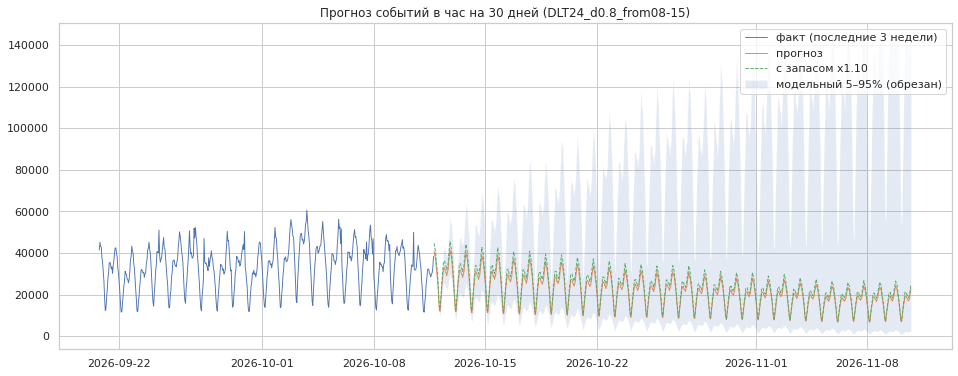

In [9]:
kind, damp, start = best_name
regs = regs_of(kind)
final = make_model(best_name, estimator='stan-mcmc' if USE_MCMC_FOR_FINAL else 'stan-map')
final.fit(act[act.hour_time >= pd.Timestamp(start)][['hour_time', 'y'] + regs])

fut = final.make_future_df(periods=24 * FORECAST_DAYS)
for d in range(1, 7):
    fut[f'dow_{d}'] = (fut.hour_time.dt.dayofweek == d).astype(int)
pred = final.predict(df=fut[['hour_time'] + regs])

out = pred[['hour_time', 'prediction_5', 'prediction', 'prediction_95']].copy()
for c in ['prediction_5', 'prediction', 'prediction_95']:
    out[c] = np.expm1(out[c]).clip(lower=0)
out.columns = ['hour_time', 'events_p5', 'events_forecast', 'events_p95']

rat = []
for (m_, h_, c_), d_ in store.items():
    if m_ == best_label:
        top = d_.forecast >= d_.forecast.quantile(0.9)
        rat.append((d_.actual[top] / d_.forecast[top]).values)
cap_factor = max(1.0, float(np.quantile(np.concatenate(rat), 0.95)))
out['events_capacity'] = out.events_forecast * cap_factor
print(f'Коэффициент запаса (P95 факт/прогноз в пиковые часы): x{cap_factor:.2f}')
out.to_csv(f'{OUT_DIR}/forecast_hourly.csv', index=False)

daily_f = out.set_index('hour_time').resample('D').agg(
    events_total=('events_forecast', 'sum'), peak_hour_forecast=('events_forecast', 'max'),
    peak_hour_capacity=('events_capacity', 'max'), peak_hour_model_p95=('events_p95', 'max'))
daily_f['peak_events_per_sec_capacity'] = daily_f['peak_hour_capacity'] / 3600
daily_f.round(1).to_csv(f'{OUT_DIR}/forecast_daily_peaks.csv')
display(daily_f.round(1).head(10))

last7 = act.events_clean.tail(24 * 7).mean()
f7 = out.events_forecast.head(24 * 7).mean()
mx_obs = act.loc[act.promo == 0, 'events'].max()
print(f'Среднее событий/час: последние 7 дней факт = {last7:,.0f}, первые 7 дней прогноза = {f7:,.0f} ({f7 / last7 - 1:+.1%})')
print(f'Максимум за всё время без акции: {mx_obs:,.0f}/час; с акцией: {act.events.max():,.0f}/час')
print(f'Прогноз events_capacity (макс.): {out.events_capacity.max():,.0f}/час (~{out.events_capacity.max() / 3600:.1f} событий/сек); '
      f'модельный P95 (макс.): {out.events_p95.max():,.0f}/час')
if out.events_p95.max() > 1.5 * act.events.max():
    print('ВНИМАНИЕ: модельный P95 в разы выше любых наблюдавшихся значений — интервал тренда раздут, '
          'для планирования используйте events_capacity.')

hist = act[act.hour_time >= act.hour_time.max() - pd.Timedelta(days=21)]
plt.figure(figsize=(16, 6))
plt.plot(hist.hour_time, hist.events, label='факт (последние 3 недели)', lw=0.9)
plt.plot(out.hour_time, out.events_forecast, label='прогноз', lw=0.9)
plt.plot(out.hour_time, out.events_capacity, label=f'с запасом x{cap_factor:.2f}', lw=0.9, ls='--')
plt.fill_between(out.hour_time, out.events_p5, out.events_p95.clip(upper=act.events.max() * 1.5),
                 alpha=0.15, label='модельный 5–95% (обрезан)')
plt.legend(); plt.title(f'Прогноз событий в час на {FORECAST_DAYS} дней ({best_label})'); plt.show()

## 8. Интерпретация: компоненты, день недели, акция

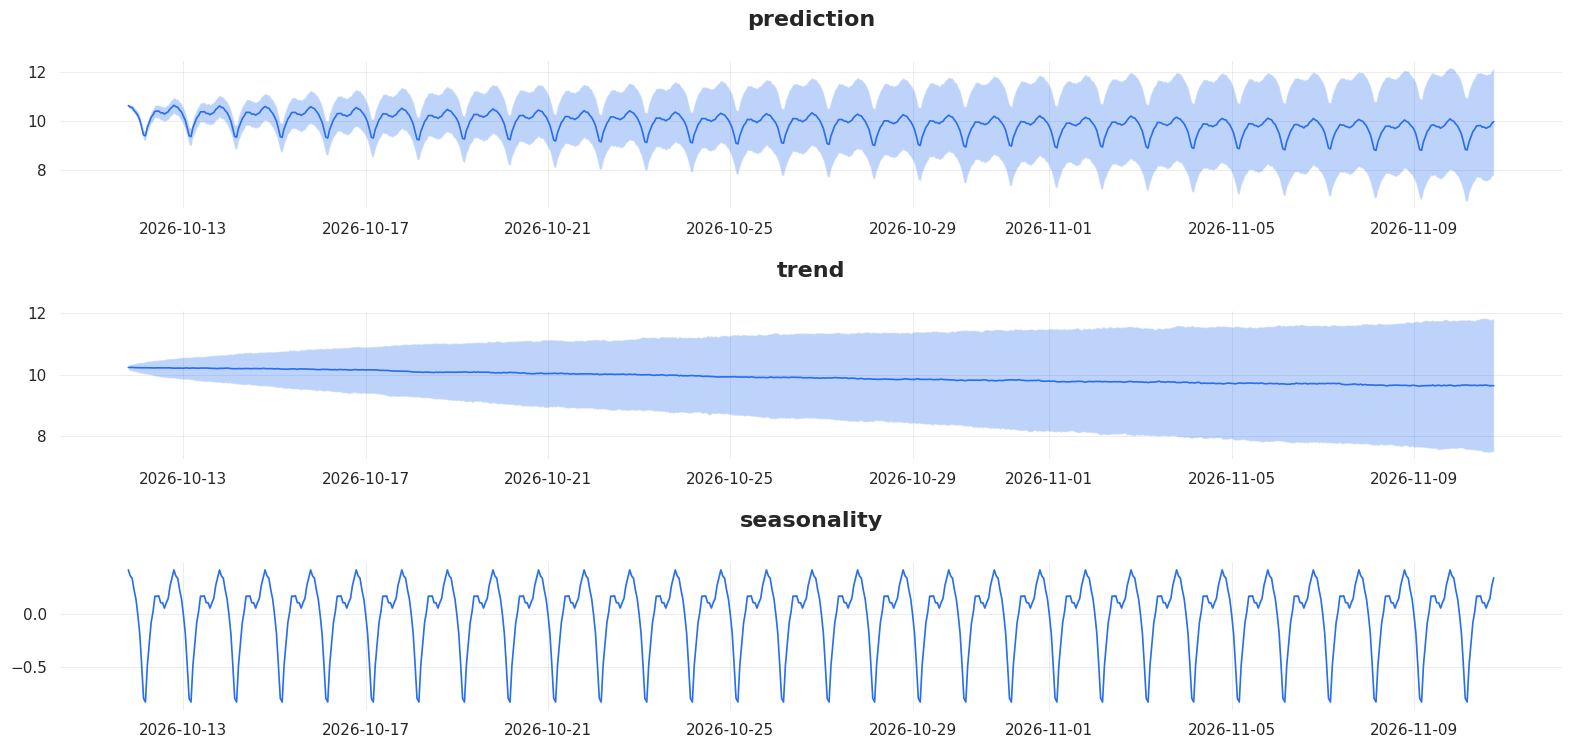

,regressor,coefficient,coefficient_lower,coefficient_upper,effect_vs_monday
0,dow_1,-0.016918,-0.041296,0.006419,-0.016776
1,dow_2,-0.027461,-0.057307,0.002350,-0.027087
2,dow_3,-0.021948,-0.057831,0.011195,-0.021709
3,dow_4,-0.038984,-0.073006,-0.005971,-0.038234
4,dow_5,-0.025017,-0.058461,0.005268,-0.024707
5,dow_6,-0.035719,-0.056251,-0.015898,-0.035089


Эффект акции 11–17.09 (факт / контрафакт): суммарно +98%, в пиковый час +103%.


In [10]:
comp = final.predict(df=fut[['hour_time'] + regs], decompose=True)
_ = plot_predicted_components(comp, 'hour_time', plot_components=['prediction', 'trend', 'seasonality'])
plt.show()

if regs:
    coefs = final.get_regression_coefs()
    coefs['effect_vs_monday'] = np.expm1(coefs['coefficient'])
    display(coefs[['regressor', 'coefficient', 'coefficient_lower', 'coefficient_upper', 'effect_vs_monday']])

print(f'Эффект акции 11–17.09 (факт / контрафакт): суммарно {up_total:+.0%}, в пиковый час {up_peak:+.0%}.')

## Ответ на вопрос 3. Выбор модели, интерпретация, ограничения

**Выбранная модель:** DLT, сезонность 24 ч + дни недели, затухание тренда 0.8, обучение с 15.08, ряд с контрафактом вместо недели акции.

**Почему:** WAPE 0.182 против 0.207 у лучшего baseline (среднее за 2 недели); особенно в пиках: peak WAPE 0.173 против 0.292, смещение −9% против −26%. Baseline систематически занижает пики, а для нагрузки они важнее всего. Модель лучше на длинных горизонтах (14 и 23 дня).

**Оговорка:** выигрыш не доказан статистически: фолдов всего 6, модель лучше baseline только в 3 из 6, на горизонте 7 дней baseline точнее; различия между вариантами затухания (WAPE 0.182–0.192) в пределах шума. На коротком горизонте простой сезонный профиль последних 2 недель — тоже разумный выбор.

**Интерпретация:**
- главный компонент — суточный цикл: ночной провал и вечерний пик (19–21 ч);
- недельный цикл слабый: эффекты дней от −1.7% до −3.7% к понедельнику, значимы только пятница и воскресенье;
- акция 11–17.09 удвоила нагрузку (+98% по сумме); максимум с акцией ~ 95.6 тыс. событий/час (~26.6/с);
- тренд модели падает на ~40% за месяц, но факт последних 3 недель плоский (прогноз на 22.5% ниже последних 7 дней) — этот спад принимать за прогноз нельзя; интервал на 30 дней раздут и пригоден максимум на 7–10 дней.

**Итог для DevOps — три сценария на 30 дней:**

| Сценарий | Пик, событий/час | Пик, событий/с |
|---|---|---|
| Модель (тренд вниз) | 41.6 тыс. | 11.5 |
| Как последние 2 недели | 53.3 тыс. | 14.8 |
| Акция повторится | 105.4 тыс. | 29.3 |

Историческая справка: максимум без акции 72.6 тыс./час (~ 20/с), с акцией 95.6 тыс./час (~ 26.6/с). Базовое планирование — по сценарию «как сейчас» с запасом до исторического максимума без акции; стресс-сценарий — повтор акции.

**Ограничения:**
1. Горизонт 30 дней не бэктестирован; надёжно подтверждены 7–23 дня, прогноз нужно пересчитывать еженедельно.
2. Данных мало (~10 недель): нет годовой сезонности и праздников.
3. Преимущество модели над baseline невелико и держится на малом числе фолдов.
4. Тренд модели не подтверждается данными, модельный интервал на месяц нереалистичен.
5. Акции непредсказуемы; контрафакт для недели акции — грубая оценка снизу.
6. Не учтены рекламные закупки, A/B-тесты, часовые пояса аудитории; событие в ленте ≠ запрос к серверу (нужен коэффициент перехода от инженеров).